# 2. Import Library


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from gensim.models.fasttext import FastText
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SEED = 42
np.random.seed(SEED)

# 3. Load Dataset

In [2]:
DATA_PATH = "dataset_preprocessed.csv"

if not os.path.exists(DATA_PATH):
    # Alternatif jika notebook dijalankan dari folder pertemuan-07
    candidates = [
        "../dataset/dataset_preprocessed.csv",
        "../dataset_preprocessed.csv"
    ]
    DATA_PATH = next((p for p in candidates if os.path.exists(p)), DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())


Lokasi dataset: ../dataset_preprocessed.csv
Ukuran dataset: (123253, 2)
Kolom: ['content', 'processed_text']


,content,processed_text
0,Mantap,mantap
1,Bagus dan mudah digunakan,bagus mudah
2,Good,good
3,Sangat membantu orang menengah mantap semoga s...,bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa


In [3]:
# Dataset milik praktikum berisi 'content' dan 'processed_text'.
# Gunakan processed_text yang sudah diproses; jika tidak ada, gunakan content.
text_column = "processed_text" if "processed_text" in df.columns else "content"
df = df.dropna(subset=[text_column]).copy()
df[text_column] = df[text_column].astype(str).str.strip()
df = df[df[text_column] != ""]

sentences = [text.split() for text in df[text_column] if text.strip()]
sentences = [tokens for tokens in sentences if tokens]

print("Kolom teks yang digunakan:", text_column)
print("Jumlah teks/kalimat:", len(sentences))
print("Contoh token:", sentences[0][:15] if sentences else "Dataset kosong")
print("Jumlah token keseluruhan:", sum(len(s) for s in sentences))

Kolom teks yang digunakan: processed_text
Jumlah teks/kalimat: 119613
Contoh token: ['mantap']
Jumlah token keseluruhan: 537966


# 4. Melatih Model Word2Vec

In [4]:
model_w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    sg=1,
    seed=SEED
)

print("Model Word2Vec (Skip-gram) berhasil dilatih.")
print("Ukuran vocabulary:", len(model_w2v.wv))


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Model Word2Vec (Skip-gram) berhasil dilatih.
Ukuran vocabulary: 9794


# 5. Menyimpan dan Load Model

In [5]:
MODEL_PATH = "word2vec_model.bin"
model_w2v.save(MODEL_PATH)
print("Model disimpan ke:", os.path.abspath(MODEL_PATH))

# Untuk memuat model yang sudah disimpan:
# model_w2v = Word2Vec.load(MODEL_PATH)


Model disimpan ke: d:\NLP\Modul-2\pertemuan-07\word2vec_model.bin


# 6. Melihat Vektor Kata

In [6]:
sample_word = "bagus"

if sample_word in model_w2v.wv:
    vector = model_w2v.wv[sample_word]
    print(f"Vektor kata '{sample_word}'")
    print("Dimensi:", vector.shape)
    print("10 nilai pertama:", vector[:10])
else:
    print(f"Kata '{sample_word}' tidak ditemukan dalam vocabulary.")
    print("Contoh kata yang tersedia:", list(model_w2v.wv.key_to_index)[:20])

Vektor kata 'bagus'
Dimensi: (100,)
10 nilai pertama: [ 0.2629885   0.51091135  0.34630182  0.1391219  -0.23419103  0.35990918
 -0.34056112  0.3860647  -0.1933281   0.2773121 ]


# 7. Mencari Kata Paling Mirip

In [7]:
def find_similar_words(word, model=model_w2v, top_n=10):
    if word not in model.wv:
        print(f"Kata '{word}' tidak ada dalam vocabulary.")
        return []
    return model.wv.most_similar(word, topn=min(top_n, len(model.wv) - 1))

test_words = ["bagus", "buruk", "mudah", "aplikasi", "saldo", "transaksi"]

for word in test_words:
    print(f"\nKata yang mirip dengan '{word}':")
    for similar_word, score in find_similar_words(word, model_w2v, top_n=5):
        print(f"  {similar_word:<20} : {score:.4f}")


Kata yang mirip dengan 'bagus':
  baguss               : 0.7869
  bagusdan             : 0.7492
  bagusss              : 0.7476
  bagussss             : 0.7334
  bguss                : 0.7299

Kata yang mirip dengan 'buruk':
  bagong               : 0.7168
  busuk                : 0.7076
  konyol               : 0.7067
  perihal              : 0.7064
  centre               : 0.7010

Kata yang mirip dengan 'mudah':
  efektif              : 0.8148
  ringkas              : 0.8012
  mudahh               : 0.7998
  pembayan             : 0.7902
  bagusmudah           : 0.7866

Kata yang mirip dengan 'aplikasi':
  apk                  : 0.8085
  aplikasinyasangat    : 0.7499
  apl                  : 0.7216
  transferbayar        : 0.7110
  siiipppp             : 0.7081

Kata yang mirip dengan 'saldo':
  mutasi               : 0.7847
  klaim                : 0.7605
  sldo                 : 0.7589
  raib                 : 0.7574
  dibatalin            : 0.7574

Kata yang mirip dengan 'transak

# 8. Similarity antar Kata

In [8]:
def word_similarity(word1, word2, model=model_w2v):
    if word1 not in model.wv or word2 not in model.wv:
        return None
    return float(model.wv.similarity(word1, word2))

pairs = [
    ("bagus", "mantap"),
    ("bagus", "buruk"),
    ("mudah", "praktis"),
    ("saldo", "topup"),
    ("transaksi", "pembayaran")
]

print("Similarity antar kata:")
for w1, w2 in pairs:
    score = word_similarity(w1, w2, model_w2v)
    if score is None:
        print(f"{w1} ↔ {w2}: salah satu kata tidak ada dalam vocabulary")
    else:
        print(f"{w1} ↔ {w2}: {score:.4f}")

Similarity antar kata:
bagus ↔ mantap: 0.5840
bagus ↔ buruk: 0.3844
mudah ↔ praktis: 0.7255
saldo ↔ topup: 0.5363
transaksi ↔ pembayaran: salah satu kata tidak ada dalam vocabulary


# 9. Operasi Vektor Kata

In [9]:
def vector_operation(positive, negative=(), top_n=5, model=model_w2v):
    missing = [w for w in list(positive) + list(negative) if w not in model.wv]
    if missing:
        print("Operasi dilewati; kata tidak ditemukan:", missing)
        return []
    result = model.wv.most_similar(
        positive=list(positive),
        negative=list(negative),
        topn=top_n
    )
    for word, score in result:
        print(f"{word:<20} : {score:.4f}")
    return result

print("Contoh operasi: bagus + mudah - buruk")
vector_operation(positive=["bagus", "mudah"], negative=["buruk"])


Contoh operasi: bagus + mudah - buruk
mudahh               : 0.7075
menggunakanya        : 0.7017
cpat                 : 0.6960
fungsional           : 0.6855
penggunaanya         : 0.6790


[('mudahh', 0.7074698209762573),
 ('menggunakanya', 0.7016654014587402),
 ('cpat', 0.695968508720398),
 ('fungsional', 0.6854949593544006),
 ('penggunaanya', 0.6790075898170471)]

# 10. Visualisasi dengan PCA

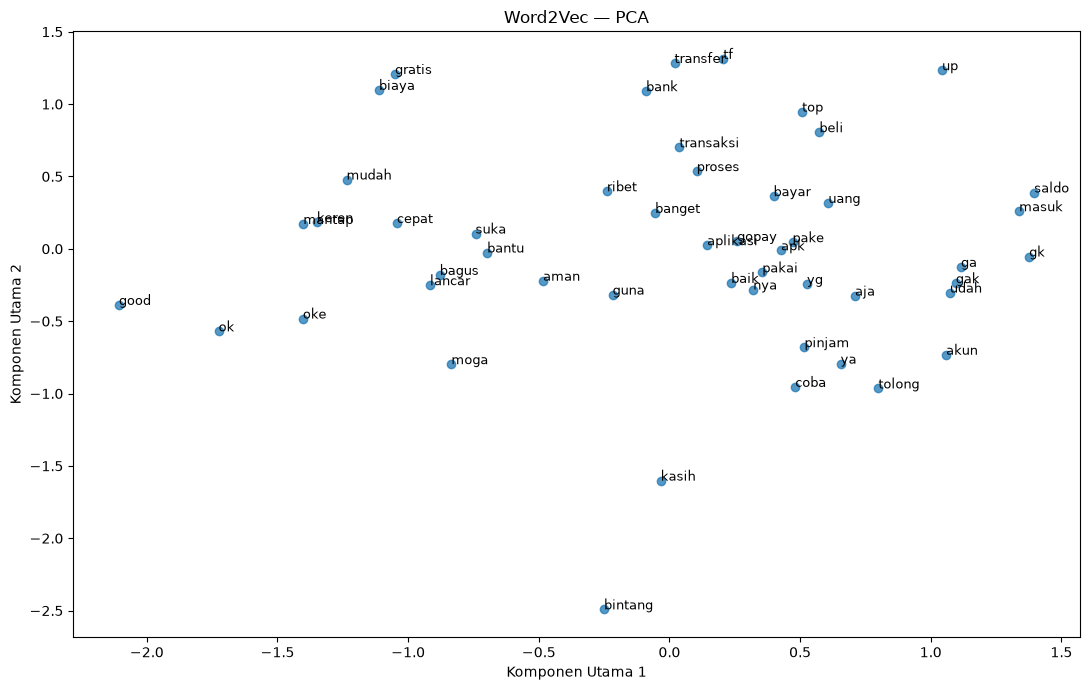

In [10]:
def visualize_embeddings_pca(words, model=model_w2v, title="Word2Vec — PCA"):
    valid_words = list(dict.fromkeys(w for w in words if w in model.wv))
    if len(valid_words) < 2:
        print("Minimal dua kata harus tersedia untuk PCA.")
        return
    vectors = np.array([model.wv[w] for w in valid_words])
    vectors_2d = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

    plt.figure(figsize=(11, 7))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.75)
    for i, word in enumerate(valid_words):
        plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=9)
    plt.title(title)
    plt.xlabel("Komponen Utama 1")
    plt.ylabel("Komponen Utama 2")
    plt.tight_layout()
    plt.show()

top_words = list(model_w2v.wv.key_to_index.keys())[:50]
visualize_embeddings_pca(top_words, model_w2v)

# 11. Visualisasi dengan t-SNE

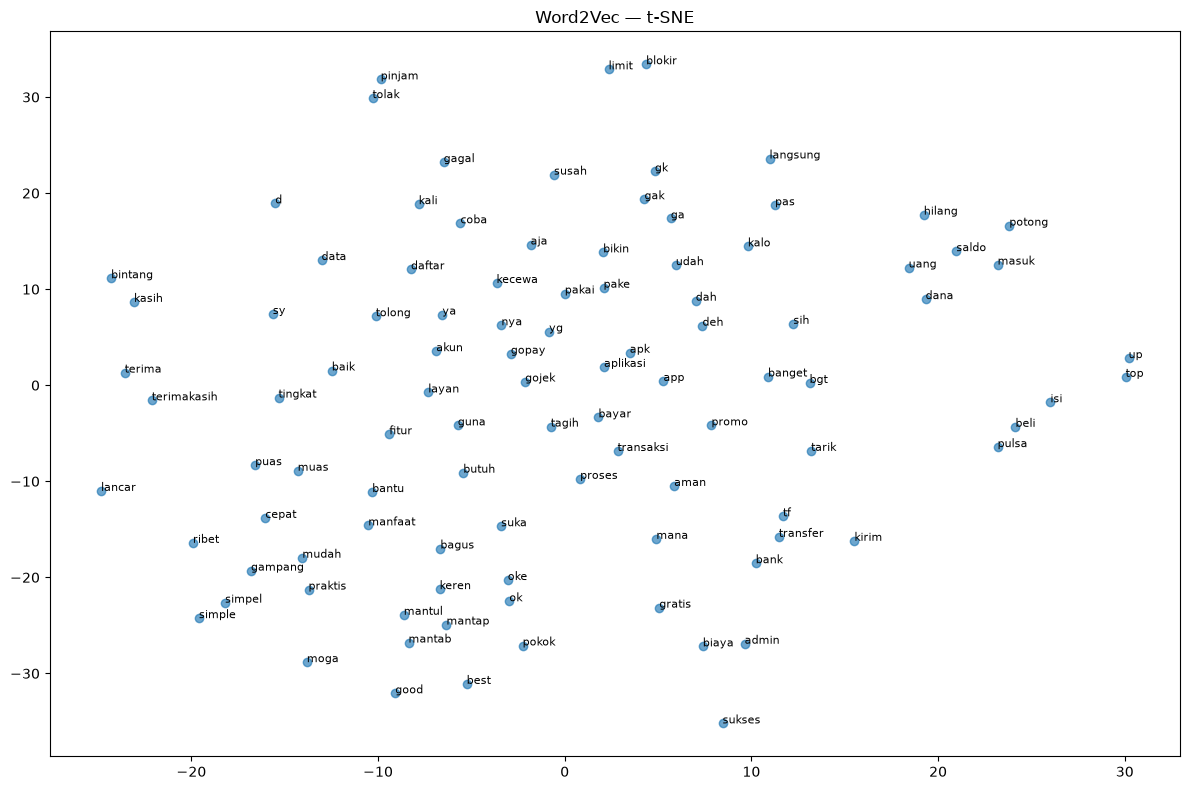

In [11]:
def visualize_embeddings_tsne(words, model=model_w2v, title="Word2Vec — t-SNE"):
    valid_words = list(dict.fromkeys(w for w in words if w in model.wv))
    if len(valid_words) < 3:
        print("Kata yang tersedia terlalu sedikit untuk t-SNE.")
        return
    vectors = np.array([model.wv[w] for w in valid_words])
    # Perplexity harus lebih kecil dari jumlah sampel.
    perplexity = min(15, len(valid_words) - 1)
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=SEED, init="pca", learning_rate="auto")
    vectors_2d = tsne.fit_transform(vectors)

    plt.figure(figsize=(12, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.65)
    for i, word in enumerate(valid_words):
        plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=8)
    plt.title(title)
    plt.tight_layout()
    plt.show()

top_words_tsne = list(model_w2v.wv.key_to_index.keys())[:100]
visualize_embeddings_tsne(top_words_tsne, model_w2v)

**Melatih Model Word2Vec — CBOW (sg=0) dan Membandingkan**

In [12]:
model_cbow = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    sg=0,
    seed=SEED
)

print("Ukuran vocabulary CBOW:", len(model_cbow.wv))
for word in ["bagus", "buruk", "mudah", "aplikasi"]:
    print(f"\nKata: {word}")
    if word in model_w2v.wv:
        print("Skip-gram:", model_w2v.wv.most_similar(word, topn=5))
    else:
        print("Skip-gram: kata tidak ada dalam vocabulary")
    if word in model_cbow.wv:
        print("CBOW:", model_cbow.wv.most_similar(word, topn=5))
    else:
        print("CBOW: kata tidak ada dalam vocabulary")


Ukuran vocabulary CBOW: 9794

Kata: bagus
Skip-gram: [('baguss', 0.786899983882904), ('bagusdan', 0.7492449879646301), ('bagusss', 0.7475974559783936), ('bagussss', 0.7333611249923706), ('bguss', 0.7298950552940369)]
CBOW: [('baguss', 0.7209147214889526), ('keren', 0.7205770015716553), ('komplit', 0.6292679905891418), ('oke', 0.6286950707435608), ('rekomendasi', 0.6207705736160278)]

Kata: buruk
Skip-gram: [('bagong', 0.7168399095535278), ('busuk', 0.7076432704925537), ('konyol', 0.7067111730575562), ('perihal', 0.7063741087913513), ('centre', 0.7009593844413757)]
CBOW: [('kecewa', 0.7637113928794861), ('jelek', 0.7246584296226501), ('costumer', 0.7123550176620483), ('sampah', 0.6955158114433289), ('bilang', 0.6815800070762634)]

Kata: mudah
Skip-gram: [('efektif', 0.8148012161254883), ('ringkas', 0.8011847138404846), ('mudahh', 0.799760103225708), ('pembayan', 0.7901970744132996), ('bagusmudah', 0.786605179309845)]
CBOW: [('gampang', 0.755957305431366), ('praktis', 0.7454186081886292)

# 12. FastText (Menangani OOV)

In [13]:
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    seed=SEED
)

oov_word = "pembayarannya"
vector_oov = model_ft.wv[oov_word]
print(f"FastText menghasilkan vektor untuk '{oov_word}'.")
print("Dimensi vektor:", vector_oov.shape)
print("Apakah kata ada di vocabulary Word2Vec?", oov_word in model_w2v.wv)
print("FastText memanfaatkan subword untuk membentuk vektor kata yang tidak dikenal.")


FastText menghasilkan vektor untuk 'pembayarannya'.
Dimensi vektor: (100,)
Apakah kata ada di vocabulary Word2Vec? False
FastText memanfaatkan subword untuk membentuk vektor kata yang tidak dikenal.


# 13. Perbandingan Word2Vec vs FastText

In [14]:
test_words_oov = ["pembayarannya", "transaksinya", "penggunaannya"]

for word in test_words_oov:
    print(f"\nKata: {word}")
    if word in model_w2v.wv:
        print("Word2Vec:", model_w2v.wv.most_similar(word, topn=5))
    else:
        print("Word2Vec: kata tidak ada dalam vocabulary (OOV)")
    # FastText dapat membentuk vektor berdasarkan subword
    print("FastText:", model_ft.wv.most_similar(word, topn=5))


Kata: pembayarannya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('pembayaranya', 0.9944115877151489), ('pembayaranny', 0.9537816643714905), ('prmbayaran', 0.9512120485305786), ('pembayaransaya', 0.9493141174316406), ('pembelianpembayaran', 0.9482471346855164)]

Kata: transaksinya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('transaksi', 0.9432536959648132), ('transaksigak', 0.9348242878913879), ('transaksitapi', 0.9316991567611694), ('transaksidan', 0.9304108023643494), ('transaksitransaksi', 0.9299033880233765)]

Kata: penggunaannya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('penggunaanya', 0.9919151067733765), ('pengoprasiannya', 0.9418177008628845), ('pengunannya', 0.9365960359573364), ('pengunaannya', 0.935016393661499), ('kegunaanya', 0.9270016551017761)]


# E. Tugas Analisis



In [15]:
# NOMOR 1
# Perbandingan CBOW dan Skip-gram
from gensim.models import Word2Vec

# Mengambil data teks yang sudah diproses
sentences = [
    str(teks).split()
    for teks in df["processed_text"].dropna()
    if str(teks).strip()
]

# Melatih model CBOW
model_cbow = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=20
)

# Melatih model Skip-gram
model_skipgram = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=20
)

# Membandingkan kata yang paling mirip
kata_uji = "saldo"
for nama, model in [
    ("CBOW", model_cbow),
    ("Skip-gram", model_skipgram)
]:
    if kata_uji in model.wv:
        print(f"\nKata paling mirip dengan '{kata_uji}' - {nama}:")
        print(model.wv.most_similar(kata_uji, topn=10))
    else:
        print(f"Kata '{kata_uji}' tidak ditemukan pada model {nama}.")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'



Kata paling mirip dengan 'saldo' - CBOW:
[('otomatis', 0.6436846852302551), ('konfirmasi', 0.634073793888092), ('duit', 0.628657877445221), ('emoney', 0.6273724436759949), ('mutasi', 0.6256192922592163), ('uang', 0.6169365048408508), ('refund', 0.6139857769012451), ('riwayat', 0.6081704497337341), ('batal', 0.5895354747772217), ('hasil', 0.5797545909881592)]

Kata paling mirip dengan 'saldo' - Skip-gram:
[('hana', 0.724854588508606), ('saldony', 0.7212803363800049), ('terkirimtapi', 0.7123002409934998), ('etol', 0.7083163261413574), ('chek', 0.7066313028335571), ('ngomongnya', 0.7048383355140686), ('sedangakan', 0.7037405967712402), ('dibatalin', 0.7021681070327759), ('transaksisaldo', 0.7010478973388672), ('kmaren', 0.7000735402107239)]


**Apa perbedaannya?**
CBOW menghasilkan kata yang lebih umum dan relevan dengan konteks saldo, seperti mutasi, uang, dan riwayat. Skip-gram menemukan beberapa kata terkait transaksi, seperti masuksaldo dan dibatalin, tetapi hasil lainnya lebih bising karena token gabungan atau typo, misalnya jelassaya dan sedangakan.

Jadi, pada hasil ini CBOW lebih mudah ditafsirkan, sedangkan Skip-gram menangkap variasi konteks yang lebih spesifik tetapi kurang bersih.

In [16]:
# NOMOR 2:
pasangan_kata = [
    ("bagus", "baik"),
    ("mudah", "gampang"),
    ("cepat", "lancar"),
    ("saldo", "uang"),
    ("aplikasi", "app")
]

for kata1, kata2 in pasangan_kata:
    print(f"\nPasangan: {kata1} - {kata2}")

    for nama, model in [
        ("CBOW", model_cbow),
        ("Skip-gram", model_skipgram)
    ]:
        if kata1 in model.wv and kata2 in model.wv:
            nilai = model.wv.similarity(kata1, kata2)
            print(f"{nama}: {nilai:.4f}")
        else:
            print(f"{nama}: kata tidak tersedia dalam kosakata model")


Pasangan: bagus - baik
CBOW: 0.2602
Skip-gram: 0.4613

Pasangan: mudah - gampang
CBOW: 0.6806
Skip-gram: 0.7340

Pasangan: cepat - lancar
CBOW: 0.2287
Skip-gram: 0.3567

Pasangan: saldo - uang
CBOW: 0.6169
Skip-gram: 0.6068

Pasangan: aplikasi - app
CBOW: 0.4856
Skip-gram: 0.5949


**Apakah model menangkap relasi tersebut?**
Kedua model menangkap beberapa relasi dengan baik, terutama mudah–gampang dan saldo–uang. 

Skip-gram menghasilkan similarity lebih tinggi pada semua pasangan ini. 
Namun, skor tersebut mencerminkan kemiripan konteks dalam dataset,

 bukan bukti pasti bahwa dua kata bersinonim.

In [17]:
# NOMOR 3:
operasi_vektor = [
    {
        "positive": ["bagus", "cepat"],
        "negative": ["buruk"]
    },
    {
        "positive": ["saldo", "transfer"],
        "negative": ["tunai"]
    },
    {
        "positive": ["mudah", "cepat"],
        "negative": ["lambat"]
    }
]

for i, operasi in enumerate(operasi_vektor, start=1):
    print(f"\nOperasi vektor {i}:")

    kata_diperlukan = (
        operasi["positive"] + operasi["negative"]
    )

    if all(kata in model_skipgram.wv for kata in kata_diperlukan):
        hasil = model_skipgram.wv.most_similar(
            positive=operasi["positive"],
            negative=operasi["negative"],
            topn=5
        )
        print(hasil)
    else:
        print("Sebagian kata tidak tersedia dalam kosakata model.")


Operasi vektor 1:
[('mantabz', 0.6480829119682312), ('terbaikkk', 0.6374161839485168), ('cpat', 0.6336147785186768), ('menggunakanya', 0.6275710463523865), ('mudah', 0.624527096748352)]

Operasi vektor 2:
[('terkirimtapi', 0.6263904571533203), ('sinarmas', 0.6037424802780151), ('masuksaldo', 0.5978309512138367), ('sea', 0.5973847508430481), ('chek', 0.5896193385124207)]

Operasi vektor 3:
[('terbaikkk', 0.6802604794502258), ('efektif', 0.6739822030067444), ('mudahcepat', 0.6700002551078796), ('dann', 0.6615396738052368), ('luarbiasa', 0.6539242267608643)]


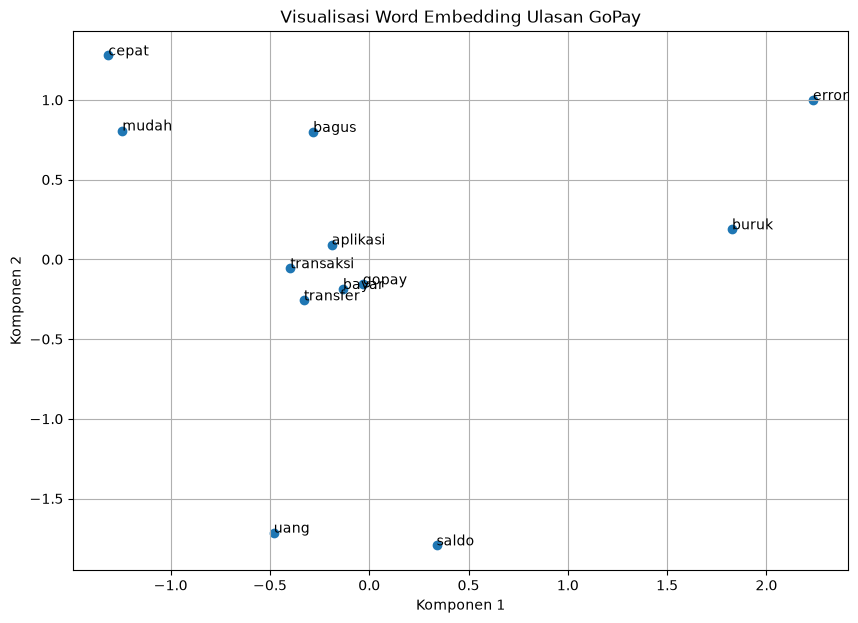

In [18]:
# NOMOR 4:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

kata_visualisasi = [
    kata for kata in [
        "gopay", "saldo", "uang", "transfer",
        "bayar", "aplikasi", "mudah", "cepat",
        "bagus", "buruk", "error", "transaksi"
    ]
    if kata in model_skipgram.wv
]

if len(kata_visualisasi) >= 2:
    vektor = [
        model_skipgram.wv[kata]
        for kata in kata_visualisasi
    ]

    pca = PCA(n_components=2)
    hasil_pca = pca.fit_transform(vektor)

    plt.figure(figsize=(10, 7))
    plt.scatter(hasil_pca[:, 0], hasil_pca[:, 1])

    for i, kata in enumerate(kata_visualisasi):
        plt.annotate(
            kata,
            (hasil_pca[i, 0], hasil_pca[i, 1])
        )

    plt.title("Visualisasi Word Embedding Ulasan GoPay")
    plt.xlabel("Komponen 1")
    plt.ylabel("Komponen 2")
    plt.grid(True)
    plt.show()
else:
    print("Jumlah kata yang tersedia belum cukup untuk visualisasi.")


In [ ]:
# NOMOR 5:
from gensim.models import FastText

# Melatih model FastText
model_fasttext = FastText(
    sentences=sentences,  # bukan kalimat
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1
)

# Kata berimbuhan Bahasa Indonesia
kata_uji = [
    "bayar",
    "membayar",
    "dibayar",
    "pembayaran",
    "transfer",
    "mentransfer"
]

for kata in kata_uji:
    print(f"\nKata: {kata}")

    # Word2Vec
    if kata in model_skipgram.wv:
        print(
            "Word2Vec:",
            model_skipgram.wv.most_similar(kata, topn=3)
        )
    else:
        print("Word2Vec: kata tidak ditemukan")

    # FastText dapat membentuk vektor dari subword
    print(
        "FastText:",
        model_fasttext.wv.most_similar(kata, topn=3)
    )

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'



Kata: bayar
Word2Vec: [('pulsabayar', 0.7342185974121094), ('indihome', 0.7071842551231384), ('jugamantap', 0.6941877007484436)]
FastText: [('kbayar', 0.9845693707466125), ('bayarbayar', 0.9810827374458313), ('bayarr', 0.979385256767273)]

Kata: membayar
Word2Vec: kata tidak ditemukan
FastText: [('membayarbgmn', 0.9914219379425049), ('pembayaranokee', 0.9905620217323303), ('pembayarann', 0.9895893335342407)]

Kata: dibayar
Word2Vec: kata tidak ditemukan
FastText: [('adadibayar', 0.9945049285888672), ('nayar', 0.9904326796531677), ('babayar', 0.9894095063209534)]

Kata: pembayaran
Word2Vec: kata tidak ditemukan
FastText: [('kpembayaran', 0.9987417459487915), ('pembayaranyg', 0.9984652996063232), ('nfcpembayaran', 0.9983369708061218)]

Kata: transfer
Word2Vec: [('tranfer', 0.7615963220596313), ('tf', 0.7586675882339478), ('trasfer', 0.7328482270240784)]
FastText: [('utransfer', 0.9956635236740112), ('transferx', 0.9954415559768677), ('uptransfer', 0.9951353669166565)]

Kata: mentransfer

# F. Pertanyaan Diskusi

**1. Mengapa dense embedding lebih baik dari sparse (BoW)?**

Dense embedding dapat menangkap hubungan makna (semantik) antar kata dan memiliki ukuran vektor yang jauh lebih kecil dan padat. Sebaliknya, sparse (BoW) berukuran sangat besar, bernilai mayoritas nol (
0), serta menganggap setiap kata berdiri sendiri tanpa hubungan makna.

**2. Apa itu "konteks" dalam Word2Vec & bagaimana menentukan makna?**

Konteks adalah kata-kata yang muncul di sekitar kata target. Berdasarkan distributional hypothesis, kata-kata yang sering muncul dalam konteks lingkungan yang sama akan dianggap memiliki makna yang mirip dan dipetakan berdekatan dalam ruang vektor.

**3. Mengapa operasi raja - pria + wanita ≈ ratu bisa terjadi?**

Karena Word2Vec mempelajari struktur hubungan linier abstrak. Mengurangi vektor 
pria dari 
raja menghapus konsep gender laki-laki dan menyisakan konsep "pemimpin kerajaan", yang jika ditambah vektor 
wanita akan mengarah ke koordinat kata 
ratu.

**4. Apa keterbatasan Word2Vec statis? (Petunjuk: pikirkan kata-kata yang memiliki makna berbeda dalam konteks berbeda)**

Word2Vec statis hanya memiliki satu vektor tetap untuk setiap kata. Hal ini membuatnya tidak bisa membedakan kata polisemi (satu kata banyak arti dalam konteks berbeda, contoh: "bisa" sebagai mampu vs racun) dan gagal menangani kata di luar kosakata (out-of-vocabulary).

**5. Mengapa FastText lebih cocok untuk Bahasa Indonesia dibandingkan Word2Vec standar?**

Bahasa Indonesia kaya akan kata berimbuhan (turunan). FastText memecah kata menjadi potongan karakter (character n-grams), sehingga tetap dapat mengenali makna kata-kata turunan baru maupun kata yang tidak ada di kamus (out-of-vocabulary) selama memiliki kata dasar yang sama.

**6. Apa yang akan diperbaiki oleh contextual embedding pada pertemuan berikutnya?**

Contextual embedding menghasilkan representasi vektor dinamis yang berubah-ubah sesuai konteks keseluruhan kalimat. Ini memperbaiki kelemahan Word2Vec statis sehingga model dapat memahami makna kata yang ambigu atau berdefinisi ganda dengan tepat.
